In [1]:
import hashlib
import os
import platform
import uuid

# 学号
STUDENT_ID = 20244080232

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] python_hw
[学号] 20244080232
[机器指纹] 98e142a17f2aaab1
[RUN_ID] 20244080232-98e142a17f2aaab1


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import kstest


In [3]:
def wigner_density(x):
    """计算Wigner半圆密度函数"""
    if abs(x) <= 2:
        return 1/(2*np.pi) * np.sqrt(4 - x**2)
    else:
        return 0.0


In [4]:
def generate_wigner(n):
    """生成n阶Wigner对称随机矩阵，方差1/n"""
    if not (isinstance(n, int) and n > 0):
        raise ValueError("n必须为正整数")
    # 上三角（含对角线）
    mat = np.random.normal(loc=0, scale=np.sqrt(1/n), size=(n,n))
    # 只保留上三角，下三角置0
    mat = np.triu(mat)
    # 转置相加得到对称矩阵，对角线不会加倍
    mat = mat + mat.T - np.diag(np.diag(mat))
    return mat


In [5]:
def get_spectrum(matrix):
    """输入numpy二维数组，返回从小到大排序的特征值数组"""
    eigvals = np.linalg.eigvalsh(matrix)
    eigvals_sorted = np.sort(eigvals)
    return eigvals_sorted


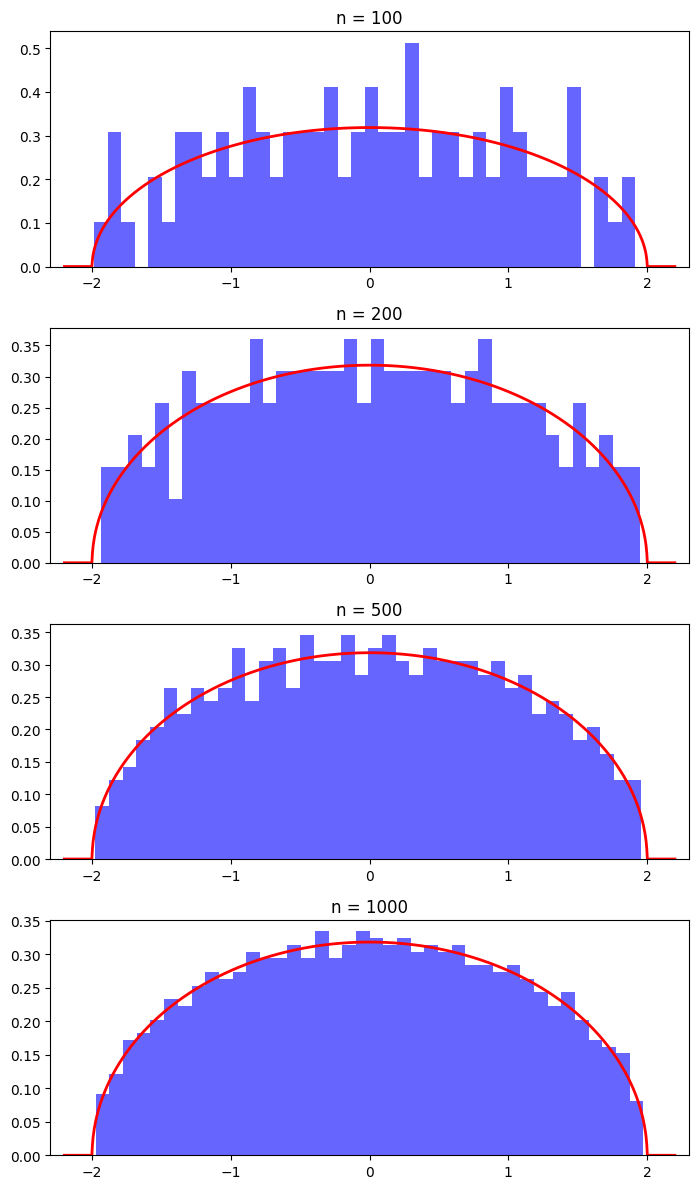

In [6]:
n_list = [100, 200, 500, 1000]
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(7,12))

x_curve = np.linspace(-2.2, 2.2, 1000)
y_curve = np.array([wigner_density(x) for x in x_curve])

for ax, n in zip(axes, n_list):
    Z = generate_wigner(n)
    ev = get_spectrum(Z)
    # 标准化直方图 density=True
    ax.hist(ev, bins=40, density=True, color="blue", alpha=0.6)
    ax.plot(x_curve, y_curve, color="red", linewidth=2)
    ax.set_title(f"n = {n}")
    ax.set_xlim(-2.3,2.3)

plt.tight_layout()
plt.show()


In [7]:
def is_valid_board(board):
    """判断是否是合法生命游戏棋盘：二维，只有0和1"""
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    unique_vals = np.unique(board)
    for v in unique_vals:
        if v not in (0,1):
            return False
    return True


In [8]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("输入不是合法生命游戏棋盘")
    b = board.astype(np.int32)
    m,n = b.shape
    # 8方向邻居求和 np.roll实现环绕
    neighbors = np.roll(b, 1, axis=0) + np.roll(b, -1, axis=0) \
              + np.roll(b, 1, axis=1) + np.roll(b, -1, axis=1) \
              + np.roll(np.roll(b,1,0), 1,1) + np.roll(np.roll(b,1,0),-1,1) \
              + np.roll(np.roll(b,-1,0),1,1)+ np.roll(np.roll(b,-1,0),-1,1)

    new_board = np.zeros_like(b)
    # 活细胞=1
    alive = b == 1
    new_board[alive & (neighbors ==2)] =1
    new_board[alive & (neighbors ==3)] =1
    # 死细胞复活
    dead = b == 0
    new_board[dead & (neighbors ==3)] =1
    return new_board


In [9]:
def draw_gol_board(board):
    plt.figure()
    plt.imshow(board, cmap="gray", vmin=0, vmax=1)
    plt.xticks([])
    plt.yticks([])
    plt.axis("off")
    plt.show()


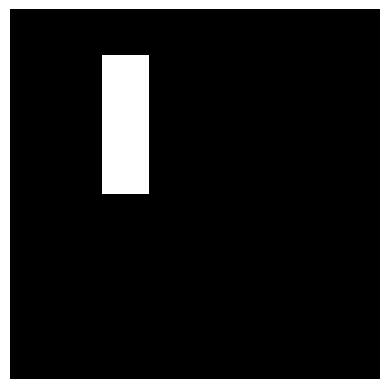

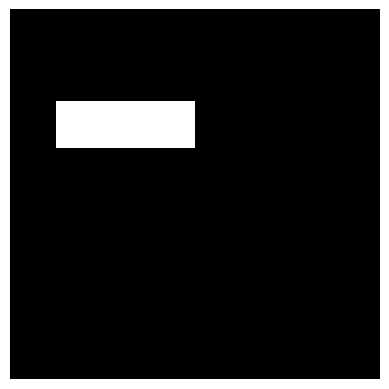

In [10]:
# 测试样例 Blinker 闪烁器
test = np.zeros((8,8), dtype=int)
test[1,2]=1
test[2,2]=1
test[3,2]=1
draw_gol_board(test)
next_test = gol_step(test)
draw_gol_board(next_test)


In [11]:
import os
print(os.getcwd())

import pandas as pd
df = pd.read_csv("iris.csv")
print("读取成功，总行数：", len(df))
df.head()


C:\Users\ACE
读取成功，总行数： 150


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [12]:
# 修改索引34
df.loc[34] = [4.9,3.1,1.5,0.2,"setosa"]
# 修改索引37
df.loc[37] = [4.9,3.6,1.4,0.1,"setosa"]

print("====索引34行====")
print(df.loc[34])
print("\n====索引37行====")
print(df.loc[37])



====索引34行====
sepal_length       4.9
sepal_width        3.1
petal_length       1.5
petal_width        0.2
species         setosa
Name: 34, dtype: object

====索引37行====
sepal_length       4.9
sepal_width        3.6
petal_length       1.4
petal_width        0.1
species         setosa
Name: 37, dtype: object


In [13]:
# 修改索引34
df.loc[34] = [4.9,3.1,1.5,0.2,"setosa"]
# 修改索引37
df.loc[37] = [4.9,3.6,1.4,0.1,"setosa"]

print("====索引34行====")
print(df.loc[34])
print("\n====索引37行====")
print(df.loc[37])


====索引34行====
sepal_length       4.9
sepal_width        3.1
petal_length       1.5
petal_width        0.2
species         setosa
Name: 34, dtype: object

====索引37行====
sepal_length       4.9
sepal_width        3.6
petal_length       1.4
petal_width        0.1
species         setosa
Name: 37, dtype: object


In [14]:
df.to_csv("iris_corrected.csv", index=False)
print("iris_corrected.csv 保存完成！")


iris_corrected.csv 保存完成！


In [15]:
print(df.columns.tolist())


['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


In [16]:
df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]

# 再次打印所有列，校验是否新增成功
print(df.columns.tolist())


['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species', 'Petal.Ratio', 'Sepal.Ratio']


In [17]:
agg_list = ["mean", "median", "min", "max", "std"]
result = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(agg_list)
result


Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188   
versicolor    3.242837  3.240385  2.666667   4.1  0.312456    2.160402   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                    
              median       min       max       std  
species                                             
setosa      1.463063  1.268293  1.956522  0.118750  
versicolor  2.161290  1.764706  2.818182  0.228658  
virginica   2.169540  1.823529  2.961538  0.246992

In [18]:
df.to_csv("iris_corrected.csv", index=False)
print("更新完成，iris_corrected.csv已经包含新增的两列")


更新完成，iris_corrected.csv已经包含新增的两列
